In [1]:
# ============================================================
# Notebook 5: Additional Defenses
# Confidence calibration, DP-SGD, data integrity checks,
# rate limiting, and model watermarking
#
# CELL 1 - Setup (shared by every cell in this notebook)
# ============================================================

import os
import json
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
np.random.seed(42)

# -- Same SimpleCNN as in notebooks 1-3 --
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1   = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2   = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU()
        self.fc1     = nn.Linear(64 * 7 * 7, 128)
        self.fc2     = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# -- MNIST normalisation (same values as notebooks 1-3) --
MEAN, STD = 0.1307, 0.3081

# A real image has pixel values between 0 (black) and 1 (white).
# After normalisation those limits become X_MIN and X_MAX.
# Any image we create must stay inside this range to be a valid image.
X_MIN = (0.0 - MEAN) / STD
X_MAX = (1.0 - MEAN) / STD

def to_tensors(dataset):
    """Load a whole MNIST split into memory as normalised tensors.
    Gives exactly the same values as ToTensor() + Normalize(), but is much faster."""
    x = dataset.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
    y = dataset.targets.clone()
    return x, y

def to_pixels(x):
    """Undo the normalisation: back to pixel values between 0 and 1."""
    return (x * STD + MEAN).clamp(0, 1)

train_set = torchvision.datasets.MNIST(root='../data', train=True,  download=False)
test_set  = torchvision.datasets.MNIST(root='../data', train=False, download=False)
X_train, y_train = to_tensors(train_set)
X_test,  y_test  = to_tensors(test_set)

def predict(model, X, batch_size=1000):
    """Return the model's raw outputs (logits) for a set of images."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            outputs.append(model(X[i:i + batch_size]))
    return torch.cat(outputs)

def accuracy(model, X, y):
    """Accuracy in percent."""
    return 100.0 * (predict(model, X).argmax(1) == y).float().mean().item()

def train_model(X, y, epochs=3, seed=0, batch_size=64, lr=0.001, desc="Training"):
    """Train a fresh SimpleCNN with the same settings as the baseline in notebook 1."""
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    n = len(X)
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n)
        for i in tqdm(range(0, n, batch_size), desc=f"{desc} epoch {epoch+1}/{epochs}"):
            idx = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X[idx]), y[idx])
            loss.backward()
            optimizer.step()
    model.eval()
    return model

def load_model(path):
    model = SimpleCNN()
    model.load_state_dict(torch.load(path, weights_only=True))
    model.eval()
    return model

os.makedirs('../figures', exist_ok=True)
os.makedirs('../results', exist_ok=True)
os.makedirs('../models',  exist_ok=True)

baseline_model = load_model('../models/mnist_cnn_baseline.pth')
print(f"Training images: {len(X_train)}   Test images: {len(X_test)}")
print(f"Baseline model clean accuracy: {accuracy(baseline_model, X_test, y_test):.2f}%")

Training images: 60000   Test images: 10000
Baseline model clean accuracy: 99.09%


Defense: Confidence Calibration (temperature scaling)
Learned temperature T = 1.089  (T > 1 means the model was over-confident)

                        Accuracy      ECE      NLL    Conf. when wrong on
                                                            FGSM examples
-------------------------------------------------------------------------
Before (T = 1)            99.60%    0.17%   0.0127                  70.8%
After  (T = 1.09)         99.60%    0.21%   0.0130                  68.6%

FGSM (epsilon=0.3) fooled the model on 4210 of 5000 evaluation images.


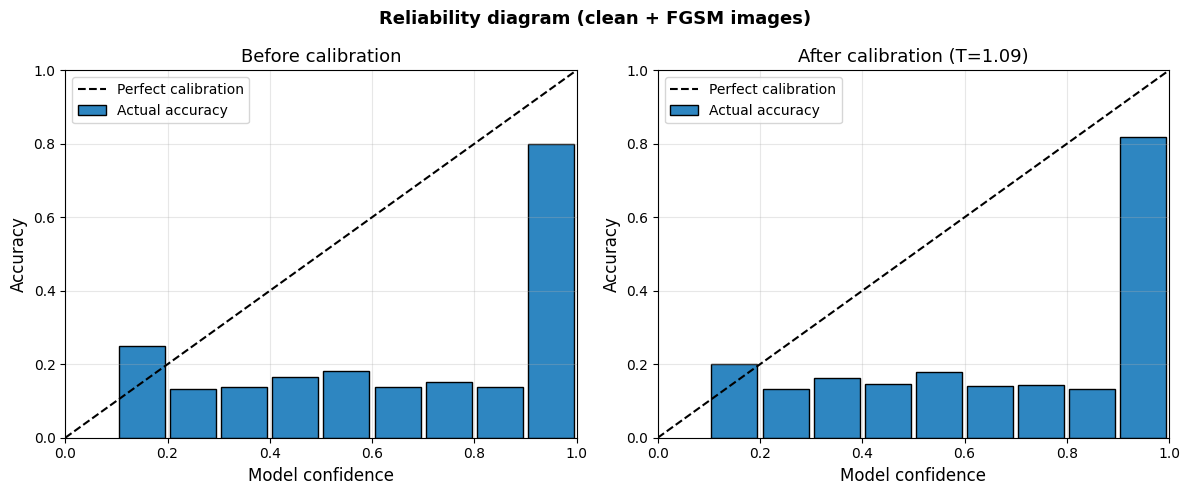


Calibration results saved!


In [2]:
# CELL 2 - Defense: Confidence calibration (temperature scaling)
# Guo et al., "On Calibration of Modern Neural Networks", 2017
#
# HOW IT WORKS:
# A model's confidence should match how often it is right: of all predictions
# made with 90% confidence, about 90% should be correct. Neural networks are
# usually OVER-confident. Temperature scaling divides the model's raw outputs
# by a single number T before the softmax. T is tuned on held-out data.
# It never changes WHICH class is predicted, so accuracy stays the same;
# it only makes the confidence values more honest.
# Why this matters for security: a system that trusts confidence scores
# (for example "accept automatically if confidence > 99%") is easier to
# fool when the model is over-confident on wrong or manipulated inputs.

EPSILON = 0.3   # attack strength in pixel units (0-1 scale), as in notebooks 2 and 3

def fgsm_attack(model, x, y, epsilon):
    """FGSM. Epsilon is in pixel units; the result is clipped to the valid image range."""
    x = x.clone().requires_grad_(True)
    loss = nn.CrossEntropyLoss()(model(x), y)
    grad, = torch.autograd.grad(loss, x)
    return torch.clamp(x + (epsilon / STD) * grad.sign(), X_MIN, X_MAX).detach()

def expected_calibration_error(probs, labels, n_bins=15):
    """ECE: average gap between confidence and accuracy (0 = perfectly calibrated)."""
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            ece += in_bin.float().mean().item() * \
                   abs(conf[in_bin].mean().item() - correct[in_bin].mean().item())
    return 100.0 * ece

print("Defense: Confidence Calibration (temperature scaling)")
print("=" * 55)

# Tune T on the first half of the test set, evaluate on the second half
X_cal,  y_cal  = X_test[:5000], y_test[:5000]
X_eval, y_eval = X_test[5000:], y_test[5000:]

cal_logits  = predict(baseline_model, X_cal)
eval_logits = predict(baseline_model, X_eval)

# Find the T that minimises the loss on the calibration half
log_T = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.LBFGS([log_T], lr=0.1, max_iter=200)
def closure():
    optimizer.zero_grad()
    loss = F.cross_entropy(cal_logits / log_T.exp(), y_cal)
    loss.backward()
    return loss
optimizer.step(closure)
T = log_T.exp().item()
print(f"Learned temperature T = {T:.3f}  (T > 1 means the model was over-confident)\n")

# Adversarial examples from the evaluation half
X_adv = torch.cat([fgsm_attack(baseline_model, X_eval[i:i + 500], y_eval[i:i + 500], EPSILON)
                   for i in range(0, len(X_eval), 500)])
adv_logits = predict(baseline_model, X_adv)

calibration_results = {}
print(f"{'':<22} {'Accuracy':>9} {'ECE':>8} {'NLL':>8} {'Conf. when wrong on':>22}")
print(f"{'':<22} {'':>9} {'':>8} {'':>8} {'FGSM examples':>22}")
print("-" * 73)
for name, temp in [("Before (T = 1)", 1.0), (f"After  (T = {T:.2f})", T)]:
    probs     = torch.softmax(eval_logits / temp, dim=1)
    adv_probs = torch.softmax(adv_logits / temp, dim=1)
    acc = 100.0 * (probs.argmax(1) == y_eval).float().mean().item()
    ece = expected_calibration_error(probs, y_eval)
    nll = F.cross_entropy(eval_logits / temp, y_eval).item()
    wrong = adv_probs.argmax(1) != y_eval
    conf_wrong = 100.0 * adv_probs.max(1)[0][wrong].mean().item()
    calibration_results[name] = (acc, ece, nll, conf_wrong)
    print(f"{name:<22} {acc:>8.2f}% {ece:>7.2f}% {nll:>8.4f} {conf_wrong:>21.1f}%")
print(f"\nFGSM (epsilon={EPSILON}) fooled the model on "
      f"{(adv_logits.argmax(1) != y_eval).sum().item()} of {len(y_eval)} evaluation images.")

# Reliability diagram: confidence vs accuracy, before and after
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, temp) in zip(axes, [("Before calibration", 1.0),
                                    (f"After calibration (T={T:.2f})", T)]):
    # Use clean + adversarial images together so the lower-confidence bins are not empty
    probs  = torch.softmax(torch.cat([eval_logits, adv_logits]) / temp, dim=1)
    labels = torch.cat([y_eval, y_eval])
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, 11)
    centres, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.sum() >= 5:
            centres.append(((lo + hi) / 2).item())
            accs.append(correct[in_bin].mean().item())
    ax.bar(centres, accs, width=0.09, color='#2e86c1', edgecolor='black',
           label='Actual accuracy')
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
    ax.set_xlabel('Model confidence', fontsize=12)
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.set_title(name, fontsize=13)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=10, loc='upper left')
    ax.grid(True, alpha=0.3)
fig.suptitle('Reliability diagram (clean + FGSM images)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/calibration_reliability.png', dpi=150)
plt.show()

with open('../results/calibration_results.txt', 'w') as f:
    f.write("Temperature Scaling Calibration Results\n")
    f.write("=" * 45 + "\n")
    f.write(f"Learned temperature T = {T:.3f}\n")
    f.write("T fitted on test images 0-4999, evaluated on test images 5000-9999\n\n")
    for name, (acc, ece, nll, conf_wrong) in calibration_results.items():
        f.write(f"{name}: accuracy={acc:.2f}%  ECE={ece:.2f}%  NLL={nll:.4f}  "
                f"mean confidence on misclassified FGSM examples={conf_wrong:.1f}%\n")
print("\nCalibration results saved!")

W1005 23:35:09.024000 5940 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Defense: Differentially Private Training (DP-SGD)
This cell trains 2 models (5 epochs each) and takes roughly 10-20 minutes on CPU.



DP-SGD (noise=1.0) epoch 5/5: 100%|██████████████████████████████████████████████████| 235/235 [00:54<00:00,  4.28it/s]



Model                    Epsilon  Train acc  Test acc  Membership AUC
----------------------------------------------------------------------
Baseline (no DP)            none     99.28%    99.09%           0.566
DP-SGD, noise=0.6           3.99     94.99%    95.33%           0.548
DP-SGD, noise=1.0           0.79     93.47%    93.56%           0.551

Epsilon is reported for delta = 1e-05. Smaller epsilon = stronger privacy.
Membership AUC of 0.5 means the attacker is only guessing.
DP model (noise=1.0) saved to models/mnist_dp_sgd.pth


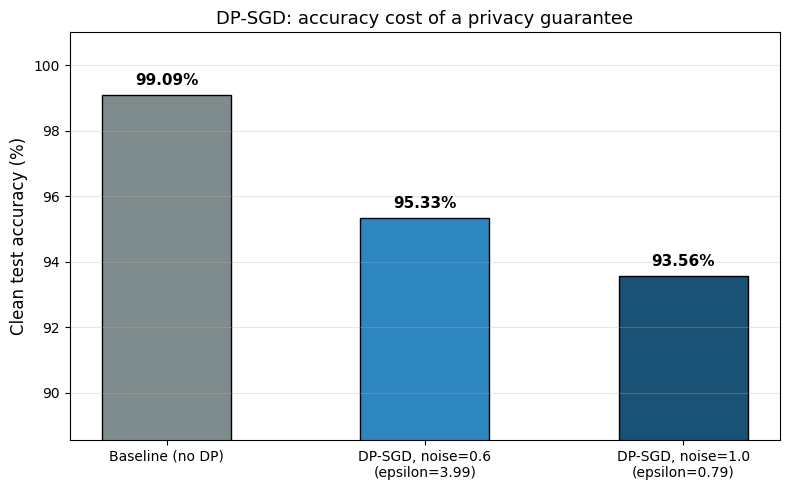

DP-SGD results saved!


In [3]:
# CELL 3 - Defense: Differentially private training (DP-SGD)
# Abadi et al., "Deep Learning with Differential Privacy", 2016
#
# HOW IT WORKS:
# Normal training lets a single training image influence the model as much
# as it likes, which is how models end up "memorising" training data.
# DP-SGD limits that influence in two steps, at every update:
#   1. Clip the gradient of EACH image so no single image can dominate
#   2. Add random noise to the summed gradients
# The result is a mathematical guarantee, measured by epsilon:
#   smaller epsilon = stronger privacy, but usually lower accuracy.
#
# This cell needs the Opacus library. If the import fails, open a
# Command Prompt, run:   conda activate thesis
#                        pip install opacus
# then restart this notebook (Kernel -> Restart & Run All).

import warnings
warnings.filterwarnings("ignore")
from opacus import PrivacyEngine
from sklearn.metrics import roc_auc_score

DELTA = 1e-5

def train_dp_model(noise_multiplier, epochs=5, max_grad_norm=1.0, batch_size=256, seed=0):
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, y_train),
        batch_size=batch_size, shuffle=True)
    privacy_engine = PrivacyEngine()
    model, optimizer, loader = privacy_engine.make_private(
        module=model, optimizer=optimizer, data_loader=loader,
        noise_multiplier=noise_multiplier, max_grad_norm=max_grad_norm)
    criterion = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        for images, labels in tqdm(loader, desc=f"DP-SGD (noise={noise_multiplier}) "
                                                f"epoch {epoch+1}/{epochs}"):
            if len(images) == 0:
                continue
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
    epsilon = privacy_engine.get_epsilon(DELTA)
    plain = SimpleCNN()                       # copy weights into a normal model
    plain.load_state_dict(model._module.state_dict())
    plain.eval()
    return plain, epsilon

def membership_auc(model, n=5000):
    """Confidence-based membership inference, summarised as AUC.
    0.5 = attacker cannot tell training images from unseen ones; 1.0 = always can."""
    member_conf     = torch.softmax(predict(model, X_train[:n]), 1).max(1)[0]
    non_member_conf = torch.softmax(predict(model, X_test[:n]),  1).max(1)[0]
    labels = np.concatenate([np.ones(n), np.zeros(n)])
    scores = torch.cat([member_conf, non_member_conf]).numpy()
    return roc_auc_score(labels, scores)

print("Defense: Differentially Private Training (DP-SGD)")
print("=" * 55)
print("This cell trains 2 models (5 epochs each) and takes roughly 10-20 minutes on CPU.\n")

dp_results = []
dp_results.append(("Baseline (no DP)", float('inf'),
                   accuracy(baseline_model, X_train[:10000], y_train[:10000]),
                   accuracy(baseline_model, X_test, y_test),
                   membership_auc(baseline_model)))

dp_models = {}
for noise in [0.6, 1.0]:
    dp_model, eps = train_dp_model(noise_multiplier=noise)
    dp_models[noise] = dp_model
    dp_results.append((f"DP-SGD, noise={noise}", eps,
                       accuracy(dp_model, X_train[:10000], y_train[:10000]),
                       accuracy(dp_model, X_test, y_test),
                       membership_auc(dp_model)))

print(f"\n{'Model':<22} {'Epsilon':>9} {'Train acc':>10} {'Test acc':>9} {'Membership AUC':>15}")
print("-" * 70)
for name, eps, train_acc, test_acc, auc in dp_results:
    eps_text = "none" if eps == float('inf') else f"{eps:.2f}"
    print(f"{name:<22} {eps_text:>9} {train_acc:>9.2f}% {test_acc:>8.2f}% {auc:>15.3f}")
print(f"\nEpsilon is reported for delta = {DELTA}. Smaller epsilon = stronger privacy.")
print("Membership AUC of 0.5 means the attacker is only guessing.")

torch.save(dp_models[1.0].state_dict(), '../models/mnist_dp_sgd.pth')
print("DP model (noise=1.0) saved to models/mnist_dp_sgd.pth")

# Figure: the privacy / accuracy trade-off
fig, ax = plt.subplots(figsize=(8, 5))
names = [r[0] + ("" if r[1] == float('inf') else f"\n(epsilon={r[1]:.2f})") for r in dp_results]
bars = ax.bar(names, [r[3] for r in dp_results],
              color=['#7f8c8d', '#2e86c1', '#1a5276'], edgecolor='black', width=0.5)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"{bar.get_height():.2f}%", ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Clean test accuracy (%)', fontsize=12)
ax.set_title('DP-SGD: accuracy cost of a privacy guarantee', fontsize=13)
ax.set_ylim(min(r[3] for r in dp_results) - 5, 101)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/dp_sgd_tradeoff.png', dpi=150)
plt.show()

with open('../results/dp_sgd_results.txt', 'w') as f:
    f.write("DP-SGD Results on MNIST\n")
    f.write("=" * 45 + "\n")
    f.write(f"Settings: 5 epochs, Adam lr 0.002, batch 256, clipping norm 1.0, delta {DELTA}\n")
    f.write("Membership AUC: confidence-based attack, 5,000 members vs 5,000 non-members\n\n")
    for name, eps, train_acc, test_acc, auc in dp_results:
        eps_text = "none" if eps == float('inf') else f"{eps:.2f}"
        f.write(f"{name}: epsilon={eps_text}  train acc={train_acc:.2f}%  "
                f"test acc={test_acc:.2f}%  membership AUC={auc:.3f}\n")
print("DP-SGD results saved!")

In [4]:
# CELL 4 - Defense: Data integrity checks
#
# HOW IT WORKS:
# Poisoning and backdoor attacks work by changing the training data or the
# saved model. A simple defence is to record a fingerprint (SHA-256 hash)
# of every data and model file when it is known to be good, and to check
# the fingerprints again before training or deployment. Changing even one
# byte of a file gives a completely different fingerprint.
# Limitation: this detects changes made AFTER the fingerprints were
# recorded. It cannot tell whether the data was already bad when collected.

import hashlib
import shutil
import tempfile

def sha256_of_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

def build_manifest(paths):
    return {p: sha256_of_file(p) for p in paths}

def verify_manifest(manifest):
    """Return a list of files that are missing or have changed."""
    problems = []
    for path, expected in manifest.items():
        if not os.path.exists(path):
            problems.append((path, "missing"))
        elif sha256_of_file(path) != expected:
            problems.append((path, "CHANGED"))
    return problems

print("Defense: Data Integrity Checks")
print("=" * 55)

raw_dir = '../data/MNIST/raw'
protected_files = sorted(
    [f"{raw_dir}/{name}" for name in os.listdir(raw_dir) if not name.endswith('.gz')] +
    ['../models/mnist_cnn_baseline.pth', '../models/mnist_adversarial_trained.pth'])

manifest = build_manifest(protected_files)
with open('../results/integrity_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

print("Fingerprints recorded:")
for path, digest in manifest.items():
    print(f"  {os.path.basename(path):<34} {digest[:16]}...")

problems = verify_manifest(manifest)
print(f"\nCheck 1 - untouched files: {len(problems)} problems found")

# Demonstration: an attacker flips ONE training label (in a temporary copy,
# so your real dataset is never modified)
tmp_dir = tempfile.mkdtemp()
labels_original = f"{raw_dir}/train-labels-idx1-ubyte"
labels_tampered = os.path.join(tmp_dir, "train-labels-idx1-ubyte")
shutil.copy(labels_original, labels_tampered)
with open(labels_tampered, 'r+b') as f:
    f.seek(8)                        # first label is stored after an 8-byte header
    first_label = f.read(1)[0]
    f.seek(8)
    f.write(bytes([(first_label + 1) % 10]))

tampered_ok = sha256_of_file(labels_tampered) == manifest[labels_original]
print(f"Check 2 - copy with ONE of 60,000 labels flipped: "
      f"{'NOT detected' if tampered_ok else 'tampering DETECTED'}")
shutil.rmtree(tmp_dir)
integrity_detected = not tampered_ok

print("\nManifest saved to results/integrity_manifest.json")

Defense: Data Integrity Checks
Fingerprints recorded:
  t10k-images-idx3-ubyte             0fa7898d509279e4...
  t10k-labels-idx1-ubyte             ff7bcfd416de3373...
  train-images-idx3-ubyte            ba891046e6505d7a...
  train-labels-idx1-ubyte            65a50cbbf4e906d7...
  mnist_adversarial_trained.pth      3f83cfb4c7c7d8fe...
  mnist_cnn_baseline.pth             dfd4a4eba7bfe37a...

Check 1 - untouched files: 0 problems found
Check 2 - copy with ONE of 60,000 labels flipped: tampering DETECTED

Manifest saved to results/integrity_manifest.json


Defense: Rate Limiting against Model Extraction
This cell trains 4 small models and takes roughly 2-3 minutes on CPU.

API setting                         Answered   Refused  Copy fidelity
----------------------------------------------------------------------
No defense                              8000         0         98.95%
Label only                              8000         0         98.90%
Limit 500 queries                        500        75         94.75%
Limit 500 queries + label only           500        75         93.60%

'Refused' counts the 100-image requests that were rejected.
Lower fidelity = the stolen copy behaves less like the original model.


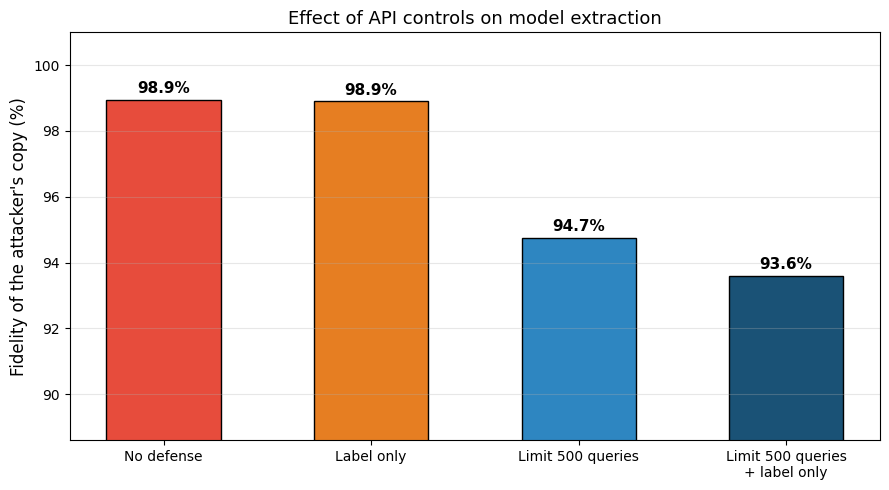


Rate limiting results saved!


In [5]:
# CELL 5 - Defense: Rate limiting against model extraction
#
# HOW IT WORKS:
# Notebook 4 showed that the more queries an attacker can send, the better
# their stolen copy becomes. Two simple controls at the prediction API:
#   1. Rate limiting : each client may only send a limited number of queries
#   2. Label only    : return just the predicted class, not the probabilities
# Limitation: an attacker who can create many accounts can spread their
# queries across them, so rate limiting should be combined with account
# controls and monitoring in a real system.

class RateLimitedAPI:
    """A prediction API that refuses a client once its query budget is used up."""
    def __init__(self, model, max_queries=None, label_only=False):
        self.model = model
        self.max_queries = max_queries
        self.label_only = label_only
        self.used = {}                                # queries used per client

    def query(self, client_id, X):
        used = self.used.get(client_id, 0)
        allowed = len(X) if self.max_queries is None else \
                  max(0, min(len(X), self.max_queries - used))
        self.used[client_id] = used + allowed
        if allowed == 0:
            return None                               # request refused
        probs = torch.softmax(predict(self.model, X[:allowed]), dim=1)
        if self.label_only:
            return F.one_hot(probs.argmax(1), 10).float()
        return probs

def train_substitute(X, soft_labels, steps=600, batch_size=64, seed=0):
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    model.train()
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch_size,))
        optimizer.zero_grad()
        log_probs = F.log_softmax(model(X[idx]), dim=1)
        loss = -(soft_labels[idx] * log_probs).sum(1).mean()
        loss.backward()
        optimizer.step()
    model.eval()
    return model

def extraction_attempt(api):
    """The attacker tries to send all 8,000 of their images, 100 at a time."""
    X_query = X_test[:8000]
    collected_x, collected_answers, refused = [], [], 0
    for i in range(0, len(X_query), 100):
        answers = api.query("attacker", X_query[i:i + 100])
        if answers is None:
            refused += 1
            continue
        collected_x.append(X_query[i:i + len(answers)])
        collected_answers.append(answers)
    X_got, answers_got = torch.cat(collected_x), torch.cat(collected_answers)
    copy = train_substitute(X_got, answers_got)
    X_holdout = X_test[8000:]
    fid = 100.0 * (predict(copy, X_holdout).argmax(1) ==
                   predict(api.model, X_holdout).argmax(1)).float().mean().item()
    return len(X_got), refused, fid

print("Defense: Rate Limiting against Model Extraction")
print("=" * 55)
print("This cell trains 4 small models and takes roughly 2-3 minutes on CPU.\n")

scenarios = [
    ("No defense",                      RateLimitedAPI(baseline_model)),
    ("Label only",                      RateLimitedAPI(baseline_model, label_only=True)),
    ("Limit 500 queries",               RateLimitedAPI(baseline_model, max_queries=500)),
    ("Limit 500 queries + label only",  RateLimitedAPI(baseline_model, max_queries=500,
                                                       label_only=True)),
]
rate_limit_results = []
print(f"{'API setting':<34} {'Answered':>9} {'Refused':>9} {'Copy fidelity':>14}")
print("-" * 70)
for name, api in scenarios:
    answered, refused, fid = extraction_attempt(api)
    rate_limit_results.append((name, answered, refused, fid))
    print(f"{name:<34} {answered:>9} {refused:>9} {fid:>13.2f}%")
print("\n'Refused' counts the 100-image requests that were rejected.")
print("Lower fidelity = the stolen copy behaves less like the original model.")

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([r[0].replace(" + ", "\n+ ") for r in rate_limit_results],
              [r[3] for r in rate_limit_results],
              color=['#e74c3c', '#e67e22', '#2e86c1', '#1a5276'], edgecolor='black', width=0.55)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            f"{bar.get_height():.1f}%", ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel("Fidelity of the attacker's copy (%)", fontsize=12)
ax.set_title('Effect of API controls on model extraction', fontsize=13)
ax.set_ylim(min(r[3] for r in rate_limit_results) - 5, 101)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/rate_limiting.png', dpi=150)
plt.show()

with open('../results/rate_limiting_results.txt', 'w') as f:
    f.write("Rate Limiting vs Model Extraction\n")
    f.write("=" * 45 + "\n")
    f.write("Attacker tries to send 8,000 queries; fidelity measured on 2,000 hold-out images\n\n")
    for name, answered, refused, fid in rate_limit_results:
        f.write(f"{name}: queries answered={answered}  requests refused={refused}  "
                f"copy fidelity={fid:.2f}%\n")
print("\nRate limiting results saved!")

Defense: Model Watermarking
This cell takes roughly 1-2 minutes on CPU.



Fine-tuning: 100%|███████████████████████████████████████████████████████████████████| 300/300 [00:05<00:00, 52.86it/s]



Model                                     Clean acc  Trigger matches  Chance of luck
------------------------------------------------------------------------------------
Baseline (no watermark)                      99.60%           16/100         4.0e-02
Adversarially trained (independent)          99.20%            8/100         7.9e-01
Watermarked model                            99.58%          100/100        1.0e-100
Stolen copy after fine-tuning                99.50%           95/100         4.5e-88

'Chance of luck' = probability that a model with no watermark would match
at least this many of the 100 secret labels by random guessing.
Watermarked model saved to models/mnist_watermarked.pth


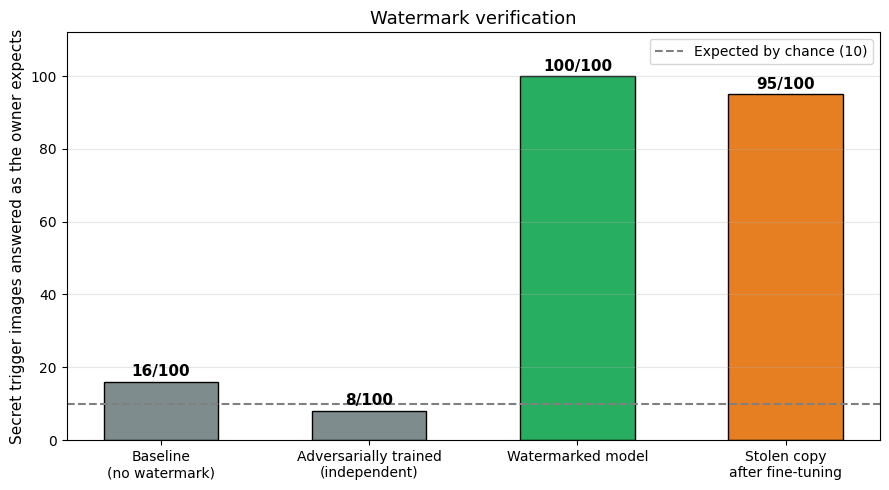

Watermarking results saved!


In [6]:
# CELL 6 - Defense: Model watermarking
# Adi et al., "Turning Your Weakness Into a Strength: Watermarking Deep
# Neural Networks by Backdooring", 2018
#
# HOW IT WORKS:
# Watermarking does not stop a model being stolen; it lets the owner PROVE
# that a model is theirs. The owner creates a secret set of random-noise
# images with random labels (the "trigger set") and trains the model to
# memorise them. No independently trained model would give those labels,
# so if a suspect model answers the trigger set correctly, it is very
# likely a copy of the owner's model.

from scipy.stats import binom

SECRET_SEED = 2026          # the owner's secret key
N_TRIGGERS  = 100

gen = torch.Generator().manual_seed(SECRET_SEED)
X_trigger = torch.rand(N_TRIGGERS, 1, 28, 28, generator=gen)       # random noise images
X_trigger = (X_trigger - MEAN) / STD
y_trigger = torch.randint(0, 10, (N_TRIGGERS,), generator=gen)     # random labels

def fine_tune(model, X_clean, y_clean, steps, X_extra=None, y_extra=None, seed=0):
    """Continue training a copy of `model` (optionally mixing in the trigger set)."""
    torch.manual_seed(seed)
    new_model = SimpleCNN()
    new_model.load_state_dict(model.state_dict())
    optimizer = torch.optim.Adam(new_model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    new_model.train()
    for _ in tqdm(range(steps), desc="Fine-tuning"):
        idx = torch.randint(0, len(X_clean), (64,))
        xb, yb = X_clean[idx], y_clean[idx]
        if X_extra is not None:
            j = torch.randint(0, len(X_extra), (16,))
            xb, yb = torch.cat([xb, X_extra[j]]), torch.cat([yb, y_extra[j]])
        optimizer.zero_grad()
        criterion(new_model(xb), yb).backward()
        optimizer.step()
    new_model.eval()
    return new_model

def watermark_check(model):
    """Trigger-set accuracy, and the probability of scoring that well by pure chance."""
    matches = int((predict(model, X_trigger).argmax(1) == y_trigger).sum().item())
    p_value = binom.sf(matches - 1, N_TRIGGERS, 0.1)     # chance of >= matches by luck
    return matches, p_value

print("Defense: Model Watermarking")
print("=" * 55)
print("This cell takes roughly 1-2 minutes on CPU.\n")

# 1. The owner embeds the watermark into the baseline model
watermarked_model = fine_tune(baseline_model, X_train, y_train, steps=400,
                              X_extra=X_trigger, y_extra=y_trigger)

# 2. A thief takes the watermarked model and fine-tunes it on their own
#    clean data, hoping to erase the watermark
stolen_model = fine_tune(watermarked_model, X_test[:5000], y_test[:5000], steps=300, seed=1)

adv_trained_model = load_model('../models/mnist_adversarial_trained.pth')

watermark_results = []
print(f"\n{'Model':<40} {'Clean acc':>10} {'Trigger matches':>16} {'Chance of luck':>15}")
print("-" * 84)
for name, model in [("Baseline (no watermark)",            baseline_model),
                    ("Adversarially trained (independent)", adv_trained_model),
                    ("Watermarked model",                   watermarked_model),
                    ("Stolen copy after fine-tuning",       stolen_model)]:
    # Clean accuracy on test images the thief did not use for fine-tuning
    clean_acc = accuracy(model, X_test[5000:], y_test[5000:])
    matches, p_value = watermark_check(model)
    watermark_results.append((name, clean_acc, matches, p_value))
    print(f"{name:<40} {clean_acc:>9.2f}% {matches:>12}/{N_TRIGGERS} {p_value:>15.1e}")
print("\n'Chance of luck' = probability that a model with no watermark would match")
print("at least this many of the 100 secret labels by random guessing.")

torch.save(watermarked_model.state_dict(), '../models/mnist_watermarked.pth')
print("Watermarked model saved to models/mnist_watermarked.pth")

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([r[0].replace(" (", "\n(").replace(" after", "\nafter") for r in watermark_results],
              [r[2] for r in watermark_results],
              color=['#7f8c8d', '#7f8c8d', '#27ae60', '#e67e22'], edgecolor='black', width=0.55)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
            f"{int(bar.get_height())}/{N_TRIGGERS}", ha='center', fontsize=11, fontweight='bold')
ax.axhline(10, color='gray', linestyle='--', label='Expected by chance (10)')
ax.set_ylabel('Secret trigger images answered as the owner expects', fontsize=11)
ax.set_title('Watermark verification', fontsize=13)
ax.set_ylim(0, 112)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/watermarking.png', dpi=150)
plt.show()

with open('../results/watermarking_results.txt', 'w') as f:
    f.write("Model Watermarking Results\n")
    f.write("=" * 45 + "\n")
    f.write(f"Trigger set: {N_TRIGGERS} random-noise images with random labels\n")
    f.write("Clean accuracy measured on test images 5000-9999\n\n")
    for name, clean_acc, matches, p_value in watermark_results:
        f.write(f"{name}: clean accuracy={clean_acc:.2f}%  "
                f"trigger matches={matches}/{N_TRIGGERS}  chance of luck={p_value:.1e}\n")
print("Watermarking results saved!")

In [7]:
# CELL 7 - Summary of this notebook

summary_lines = []
summary_lines.append("1. Confidence calibration (temperature scaling)")
for name, (acc, ece, nll, conf_wrong) in calibration_results.items():
    summary_lines.append(f"   {name}: accuracy {acc:.2f}%, ECE {ece:.2f}%, "
                         f"confidence when wrong on FGSM examples {conf_wrong:.1f}%")
summary_lines.append("")
summary_lines.append("2. DP-SGD (differentially private training)")
for name, eps, train_acc, test_acc, auc in dp_results:
    eps_text = "none" if eps == float('inf') else f"{eps:.2f}"
    summary_lines.append(f"   {name}: epsilon {eps_text}, test accuracy {test_acc:.2f}%, "
                         f"membership AUC {auc:.3f}")
summary_lines.append("")
summary_lines.append("3. Data integrity checks")
summary_lines.append(f"   {len(manifest)} files fingerprinted; single flipped label "
                     f"{'detected' if integrity_detected else 'NOT detected'}")
summary_lines.append("")
summary_lines.append("4. Rate limiting vs model extraction")
for name, answered, refused, fid in rate_limit_results:
    summary_lines.append(f"   {name}: {answered} queries answered, copy fidelity {fid:.2f}%")
summary_lines.append("")
summary_lines.append("5. Model watermarking")
for name, clean_acc, matches, p_value in watermark_results:
    summary_lines.append(f"   {name}: clean accuracy {clean_acc:.2f}%, "
                         f"trigger matches {matches}/{N_TRIGGERS}")

print("=" * 60)
print("ADDITIONAL DEFENSES - SUMMARY")
print("=" * 60 + "\n")
print("\n".join(summary_lines))

with open('../results/ADDITIONAL_DEFENSES_SUMMARY.txt', 'w') as f:
    f.write("ADDITIONAL DEFENSES - SUMMARY\n")
    f.write("=" * 60 + "\n\n")
    f.write("\n".join(summary_lines) + "\n")
print("\nSummary saved to results/ADDITIONAL_DEFENSES_SUMMARY.txt")

ADDITIONAL DEFENSES - SUMMARY

1. Confidence calibration (temperature scaling)
   Before (T = 1): accuracy 99.60%, ECE 0.17%, confidence when wrong on FGSM examples 70.8%
   After  (T = 1.09): accuracy 99.60%, ECE 0.21%, confidence when wrong on FGSM examples 68.6%

2. DP-SGD (differentially private training)
   Baseline (no DP): epsilon none, test accuracy 99.09%, membership AUC 0.566
   DP-SGD, noise=0.6: epsilon 3.99, test accuracy 95.33%, membership AUC 0.548
   DP-SGD, noise=1.0: epsilon 0.79, test accuracy 93.56%, membership AUC 0.551

3. Data integrity checks
   6 files fingerprinted; single flipped label detected

4. Rate limiting vs model extraction
   No defense: 8000 queries answered, copy fidelity 98.95%
   Label only: 8000 queries answered, copy fidelity 98.90%
   Limit 500 queries: 500 queries answered, copy fidelity 94.75%
   Limit 500 queries + label only: 500 queries answered, copy fidelity 93.60%

5. Model watermarking
   Baseline (no watermark): clean accuracy 99.60%